# Data Understanding
<div dir="rtl" style="text-align: right">

## بخش اول: شناخت اولیه دیتاست

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../OnlineRetail.csv")


<div dir="rtl" style="text-align: right">

---

### Question 1
:تعداد سطر و ستون را مشخص کنید

</div>

In [4]:
print(f"Dataset Shape (the right number is the columns(features) number and the left number is rows (records)):\n\n {df.shape}")

Dataset Shape (the right number is the columns(features) number and the left number is rows (records)):

 (541909, 8)


<div dir="rtl" style="text-align: right">

---

### Question 2
نام و نوع داده ای هر ستون چیست؟

</div>

In [5]:
print(f"the name of columns: \n {df.columns}\n")

print("\nData Types: ")

for column in df.columns:
    print(f"{column}: {df[column].dtype}")



the name of columns: 
 Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')


Data Types: 
InvoiceNo: str
StockCode: str
Description: str
Quantity: int64
InvoiceDate: str
UnitPrice: float64
CustomerID: float64
Country: str


<div dir="rtl" style="text-align: right">

---

### Question 3
هر ستون عددی، دسته‌ای یا دودویی است؟




عددی (Numerical): مقادیر کمی و قابل اندازه‌گیری هستند.

دسته‌ای (Categorical): مقادیر کیفی و گروه‌بندی شده هستند. 

دودویی (Binary): زیرمجموعه‌ای از داده‌های دسته‌ای هستند که فقط دو مقدار دارند (مثلاً sex با مقادیر ۰ و ۱)


</div>

In [7]:
feature_nature_types = {
    "InvoiceNo": "Categorical",
    "StockCode": "Categorical",
    "Description": "Categorical",
    "Quantity": "Numerical",
    "InvoiceDate": "Categorical",
    "UnitPrice": "Numerical",
    "CustomerID": "Categorical",
    "Country": "Categorical"
}

for feature, feature_type in feature_nature_types.items():
    print(f"{feature}:\t{feature_type}")

InvoiceNo:	Categorical
StockCode:	Categorical
Description:	Categorical
Quantity:	Numerical
InvoiceDate:	Categorical
UnitPrice:	Numerical
CustomerID:	Categorical
Country:	Categorical


<div dir="rtl" style="text-align: right">

---

### Question 4
از دید کسب‌وکار هر ستون چه مفهومی دارد؟

</div>

<div dir="rtl" style="text-align: right;">


| **ستون** | **مفهوم کسب‌وکار** |
|---|---|
| InvoiceNo | شماره فاکتور یا شناسه سفارش مشتری |
| StockCode | کد شناسایی محصول خریداری‌شده |
| Description | نام و توضیحات محصول |
| Quantity | تعداد کالای خریداری شده |
| InvoiceDate | تاریخ تراکنش |
| UnitPrice | قیمت هر واحد از محصول |
| CustomerID | شناسه منحصربه‌فرد مشتری |
| Country | کشور خرید مشتری |

</div>

<div dir="rtl" style="text-align: right">

---

## بخش ۲: کیفیت داده

### Question 5
در هر ستون چند مقدار Null وجود دارد؟

</div>

In [9]:
null_counts = df.isnull().sum()

print(null_counts)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


<div dir="rtl" style="text-align: right">

---

### Question 6
درصد داده‌های گمشده (missing value) هر ستون چقدر است؟


ابتدا تعداد مقادیر Null محاسبه می‌شود.

سپس بر تعداد کل رکوردها تقسیم شده و در 100 ضرب می‌شود تا درصد داده‌های گمشده به دست آید.

</div>

In [11]:
missing_value_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_value_percentage)

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64


<div dir="rtl" style="text-align: right">

---

### Question 7
آیا رکورد تکراری وجود دارد؟

تابع duplicated() تمام ردیف‌هایی را که کاملاً مشابه یک ردیف قبلی هستند شناسایی می‌کند.

سپس با استفاده از sum() تعداد آن‌ها محاسبه می‌شود.


</div>

In [3]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate Rows: {duplicate_count}")


print("\nduplicates: ")
duplicates = df[df.duplicated()]

duplicates

Duplicate Rows: 5268

duplicates: 


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,12/9/2011 11:34,0.39,14446.0,United Kingdom
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,12/9/2011 11:34,2.49,14446.0,United Kingdom
541692,581538,22992,REVOLVER WOODEN RULER,1,12/9/2011 11:34,1.95,14446.0,United Kingdom
541699,581538,22694,WICKER STAR,1,12/9/2011 11:34,2.10,14446.0,United Kingdom


<div dir="rtl" style="text-align: right">

---

### Question 8
تعداد رکوردهای تکراری چند عدد و چند درصد کل داده است؟

</div>

In [19]:
duplicate_count = df.duplicated().sum()

duplicate_percent = (duplicate_count / len(df)) * 100

print(f"The Number Of Duplicate Rows : {duplicate_count}")
print(f"The Percentage Of Duplicates : {duplicate_percent:.2f}%")

The Number Of Duplicate Rows : 5268
The Percentage Of Duplicates : 0.97%


<div dir="rtl" style="text-align: right">

---
## بخش 3: تحلیل ویژگی‌های عددی



### Question 9
آمار توصیفی کامل ویژگی‌های عددی را استخراج کنید.

آمار توصیفی اطلاعاتی مانند:

تعداد داده‌ها

میانگین

انحراف معیار

کمینه

چارک‌ها

بیشینه

را در اختیار قرار می‌دهد.

</div>

In [31]:
df.drop(columns=["CustomerID"]).describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


<div dir="rtl" style="text-align: right">

---

### Question 10
برای هر ویژگی عددی:

میانگین (Mean)،
میانه (Median) و
مد (Mode)
را محاسبه کنید.

</div>

In [32]:
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns
numeric_columns = numeric_columns.drop("CustomerID", errors="ignore")

summary = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0]
})

print(summary)

               Mean  Median  Mode
Quantity   9.552250    3.00  1.00
UnitPrice  4.611114    2.08  1.25


<div dir="rtl" style="text-align: right">


با مقایسه میانگین و میانه می‌توان میزان تقارن توزیع هر ویژگی را بررسی کرد.
اگر میانگین و میانه بسیار نزدیک باشند، احتمالاً توزیع داده متقارن است.

اگر اختلاف قابل توجهی وجود داشته باشد، ممکن است داده دارای چولگی (Skewness) یا داده‌های پرت باشد.


>چولگی (Skewness) میزان عدم تقارن توزیع داده‌ها را نشان می‌دهد؛ یعنی مشخص می‌کند داده‌ها بیشتر به کدام سمت متمایل هستند

سه حالت اصلی دارد:
1. چولگی مثبت (راست‌چوله): دنباله توزیع به سمت راست کشیده شده و بیشتر داده‌ها در مقادیر پایین‌تر قرار دارند.
2. چولگی منفی (چپ‌چوله): دنباله توزیع به سمت چپ کشیده شده و بیشتر داده‌ها در مقادیر بالاتر قرار دارند.
3. چولگی صفر: توزیع تقریباً متقارن است.



###  بررسی چولگی داده‌ها در این پروژه (Skewness)

با مقایسه میانگین، میانه و نما در ستون‌های عددی مشاهده می‌شود:

**Mean > Median > Mode**

بنابراین، ستون‌های `Quantity` و `UnitPrice` نشانه‌هایی از **چولگی مثبت (راست‌چوله)** دارند؛ یعنی بیشتر مقادیر در محدوده پایین‌تر قرار گرفته‌اند و تعداد کمی مقدار بزرگ، میانگین را افزایش داده‌اند.

برای بررسی دقیق‌تر، مقدار چولگی هر ستون محاسبه می‌شود:


</div>

In [33]:
df[["Quantity", "UnitPrice"]].skew()

Quantity      -0.264076
UnitPrice    186.506972
dtype: float64

<div dir="rtl" style="text-align: right;">

### تفسیر چولگی داده‌ها

- **Quantity (-0.26):** چولگی منفی و بسیار خفیف دارد؛ بنابراین توزیع آن تقریباً متقارن است.
- **UnitPrice (186.50):** چولگی مثبت بسیار شدید دارد؛ یعنی بیشتر قیمت‌ها پایین هستند و تعداد کمی قیمت بسیار بالا باعث کشیده‌شدن توزیع به سمت راست شده‌اند.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 11

برای هر ویژگی عددی:
واریانس (Variance) و
انحراف معیار (Standard Deviation)
را محاسبه کنید.

توابع var() و std() در Pandas محاسبه این شاخص‌ها را بسیار ساده و سریع انجام می‌دهند.

</div>

In [8]:
numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns
numeric_columns = numeric_columns.drop("CustomerID", errors="ignore")

spread = pd.DataFrame({
    "Variance": df[numeric_columns].var(),
    "Std": df[numeric_columns].std()
})

print(spread)

               Variance         Std
Quantity   47559.391409  218.081158
UnitPrice   9362.469164   96.759853


<div dir="rtl" style="text-align: right">

---

### Question 12
برای ویژگی‌های عددی Histogram رسم کنید.

با استفاده از Histogram می‌توان موارد زیر را بررسی کرد:

شکل توزیع، 
چولگی (Skewness)، 
تمرکز داده‌ها و
وجود داده‌های پرت

</div>

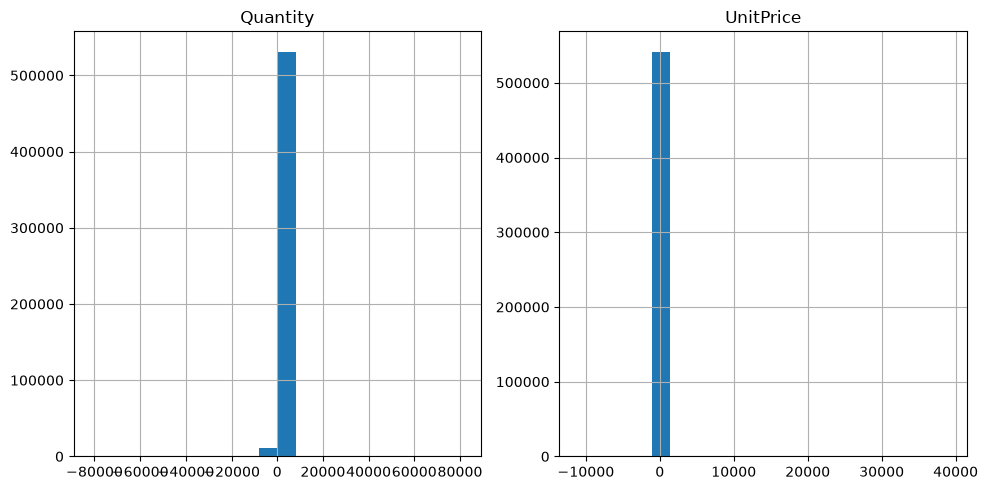

In [12]:
df[numeric_columns].hist(
    figsize=(10, 5),
    bins=20
)

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right">

---

### توضیح boxplot :

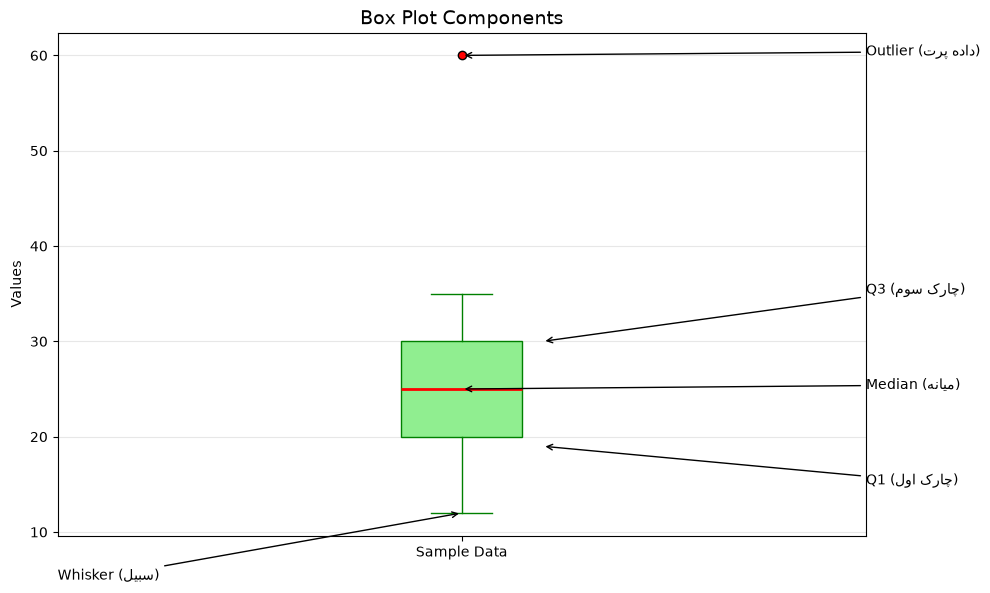

In [17]:
data = [12, 15, 18, 20, 22, 24, 25, 27, 28, 30, 32, 35, 60]

fig, ax = plt.subplots(figsize=(10, 6))

# رسم نمودار
ax.boxplot(
    data,
    patch_artist=True,
    boxprops=dict(facecolor="lightgreen", color="green"),
    medianprops=dict(color="red", linewidth=2),
    whiskerprops=dict(color="green"),
    capprops=dict(color="green"),
    flierprops=dict(marker="o", markerfacecolor="red")
)

# توضیحات اجزای نمودار
ax.annotate("Q3 (چارک سوم)", xy=(1.1, 30), xytext=(1.5, 35),
            arrowprops=dict(arrowstyle="->"))

ax.annotate("Median (میانه)", xy=(1, 25), xytext=(1.5, 25),
            arrowprops=dict(arrowstyle="->"))

ax.annotate("Q1 (چارک اول)", xy=(1.1, 19), xytext=(1.5, 15),
            arrowprops=dict(arrowstyle="->"))

ax.annotate("Whisker (سبیل)", xy=(1, 12), xytext=(0.5, 5),
            arrowprops=dict(arrowstyle="->"))

ax.annotate("Outlier (داده پرت)", xy=(1, 60), xytext=(1.5, 60),
            arrowprops=dict(arrowstyle="->"))

# تنظیمات نمودار
ax.set_title("Box Plot Components", fontsize=14)
ax.set_ylabel("Values")
ax.set_xticks([1])
ax.set_xticklabels(["Sample Data"])
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 13
برای ویژگی‌های عددی Boxplot رسم کنید.



این نمودار اطلاعاتی مانند:

میانه
چارک اول، 
چارک سوم، 
دامنه بین چارکی (IQR) و
داده‌های پرت
را به‌صورت خلاصه نمایش می‌دهد.

</div>

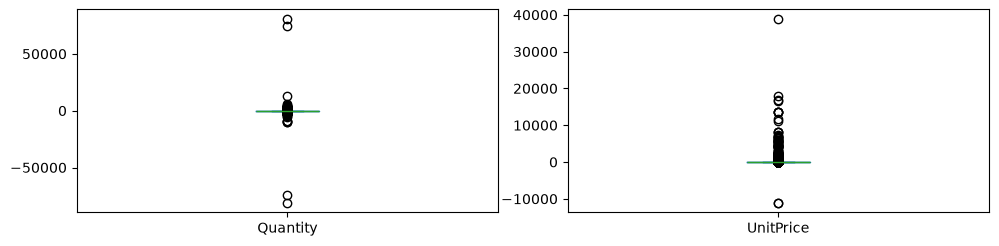

In [10]:
df[numeric_columns].plot(
    kind="box",
    subplots=True,
    layout=(5,3),
    figsize=(15,12)
)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right">

---

### Question 14
برای ویژگی‌های عددی KDE Plot رسم کنید.

KDE یک منحنی نرم از توزیع احتمال داده‌ها رسم می‌کند.

این نمودار کمک می‌کند:

شکل واقعی توزیع بهتر دیده شود. 
 وجود چند قله (Multi-modal Distribution) بررسی شود.
میزان چولگی (Skewness) بهتر مشخص گردد. 
مقایسه ویژگی‌ها ساده‌تر شود. 


</div>

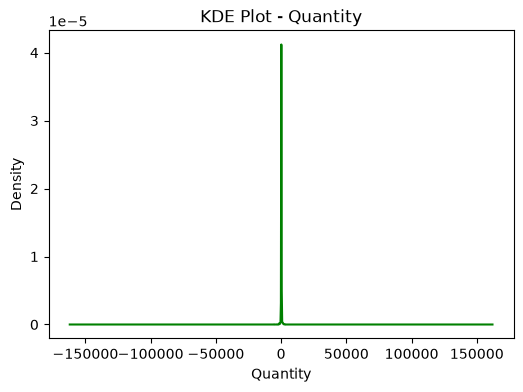

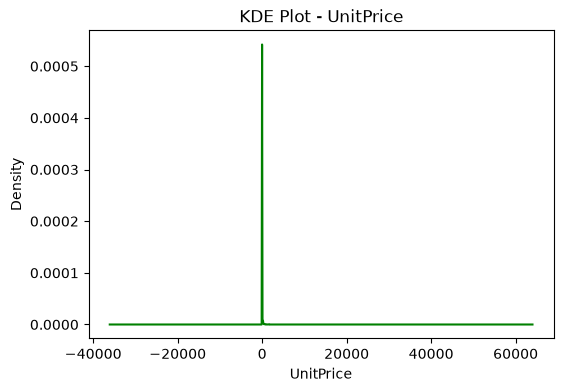

In [13]:
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("CustomerID", errors="ignore")

for column in numeric_columns:

    plt.figure(figsize=(6, 4))

    df[column].plot(
        kind="kde",
        color="green"
    )

    plt.title(f"KDE Plot - {column}")
    plt.xlabel(column)
    plt.ylabel("Density")

<div dir="rtl" style="text-align: right">

### تحلیل نمودار KDE


نمودار KDE برای بررسی توزیع و میزان تمرکز داده‌های عددی استفاده می‌شود.

- **Quantity:** نشان می‌دهد تعداد کالاهای خریداری‌شده در سفارش‌ها بیشتر در چه محدوده‌ای متمرکز شده است.
- **UnitPrice:** نشان می‌دهد قیمت کالاها بیشتر در چه محدوده‌ای قرار دارد و پراکندگی قیمت‌ها چگونه است.
- **Density:** میزان تمرکز داده‌ها در هر محدوده را نشان می‌دهد؛ هرچه ارتفاع منحنی بیشتر باشد، داده‌های بیشتری در آن محدوده متمرکز شده‌اند.

**نتیجه‌گیری:** این نمودار به شناخت بهتر الگوی خرید، پراکندگی تعداد کالاها و قیمت محصولات کمک می‌کند و می‌تواند در مراحل بعدی آماده‌سازی داده‌ها و استخراج ویژگی‌های مرتبط با رفتار مشتریان مفید باشد.

در این پروژه ما توزیع داده‌ها به‌درستی قابل نمایش نیست؛ احتمالاً به‌دلیل وجود مقادیر پرت و اختلاف مقیاس زیاد داده‌ها، منحنی KDE فشرده شده و به شکل یک خط صاف دیده می‌شود.

</div>

<div dir="rtl" style="text-align: right">

---

## بخش 4: لغو سفارش و مقادیر مشکوک

### Question 15
چند فاکتور لغوشده (پیشوند C) داریم؟

</div>

In [15]:
is_cancel = df["InvoiceNo"].astype(str).str.startswith("C")

print("Cancelled rows:", is_cancel.sum())
print("Percent:", round(is_cancel.mean() * 100, 2), "%")

Cancelled rows: 9288
Percent: 1.71 %


<div dir="rtl" style="text-align: right">

---

### Question 16
چند Quantity منفی داریم و ارتباطشان با پیشوند C چیست؟

</div>

In [16]:
neg_qty = df["Quantity"] < 0

print("Negative Quantity:", neg_qty.sum())
print("Negative AND Cancelled:", (neg_qty & is_cancel).sum())
print("Negative but NOT Cancelled:", (neg_qty & ~is_cancel).sum())

Negative Quantity: 10624
Negative AND Cancelled: 9288
Negative but NOT Cancelled: 1336


<div dir="rtl" style="text-align: right">

---

### Question 17
چند UnitPrice صفر یا منفی داریم؟

</div>

In [17]:
print("UnitPrice == 0:", (df["UnitPrice"] == 0).sum())
print("UnitPrice < 0:", (df["UnitPrice"] < 0).sum())

df[df["UnitPrice"] <= 0].head()

UnitPrice == 0: 2515
UnitPrice < 0: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom


<div dir="rtl" style="text-align: right">

---

### Question 18
آیا StockCodeهایی وجود دارند که محصول واقعی نیستند (مثل POST و BANK CHARGES)؟


**با پاسخ به این سؤال متوجه می‌شویم:**
- هزینه پست یا کارمزد خرید کالا نیست و تنوع محصول را اشتباه نشان می‌دهد.

**جواب:** کدهایی مثل POST، D (تخفیف)، M (دستی)، DOT و BANK CHARGES محصول فیزیکی نیستند. در شمارش «تعداد محصولات متمایز» باید کنار گذاشته شوند. بخشی از کدهای حرفی‌دار محصول واقعی‌اند (مثل 85123A)، پس باید دقیق بررسی شود.


</div>

In [18]:
codes = df["StockCode"].astype(str)
non_product = df[codes.str.match(r"^[A-Za-z]")] 
print(non_product["StockCode"].value_counts().head(10))

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
Name: count, dtype: int64


<div dir="rtl" style="text-align: right">

---

## بخش ۵: تحلیل ویژگی‌های دسته‌ای

### Question 19
فراوانی کشورها را محاسبه کنید.

</div>

In [ ]:
print(df["Country"].value_counts().head(10))

print((df["Country"].value_counts(normalize=True) * 100).head(5).round(2))

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64
Country
United Kingdom    91.43
Germany            1.75
France             1.58
EIRE               1.51
Spain              0.47
Name: proportion, dtype: float64


<div dir="rtl" style="text-align: right">

**با پاسخ به این سؤال متوجه می‌شویم:**

- غلبه یک کشور بر داده، و اینکه تحلیل بر اساس کشور معنادار است یا نه.

### تحلیل فراوانی کشورها

بیشترین تراکنش‌های دیتاست مربوط به کشور **United Kingdom با 91.43٪** است. پس از آن آلمان، فرانسه و ایرلند سهم بسیار کمتری دارند.

**نتیجه‌گیری:** دیتاست از نظر جغرافیایی توزیع متعادلی ندارد و بخش عمده تراکنش‌ها مربوط به بریتانیاست. بنابراین هنگام تحلیل رفتار مشتریان باید این عدم توازن جغرافیایی را در نظر بگیریم.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 20
برای ویژگی دسته‌ای کشور Countplot رسم کنید.

</div>

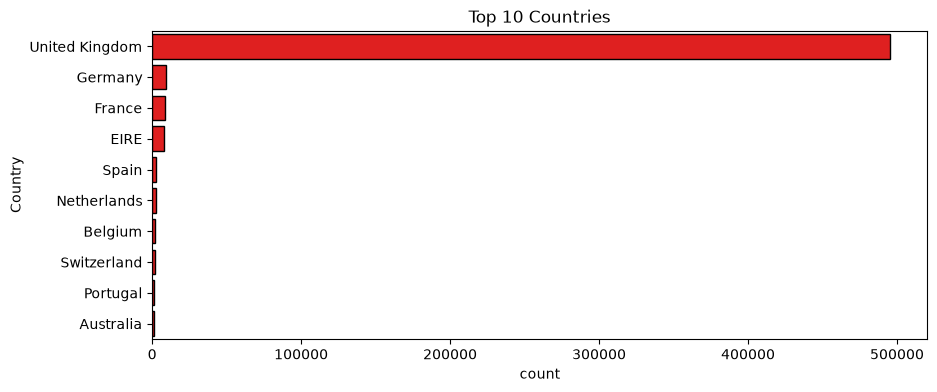

In [26]:
top_countries = df["Country"].value_counts().head(10).index
plt.figure(figsize=(10, 4))
sns.countplot(
    data=df[df["Country"].isin(top_countries)],
    y="Country",
    order=top_countries,
    color="red",
    edgecolor="black",
    )
plt.title("Top 10 Countries")
plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 21
پرتکرارترین محصولات کدام‌اند؟

</div>

In [22]:
print(df["Description"].value_counts().head(10))

Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
Name: count, dtype: int64


<div dir="rtl" style="text-align: right">

---

## بخش ۶: تحلیل زمانی و رفتار مشتری

### Question 22
تعداد فاکتورها در هر ماه چگونه است؟

</div>

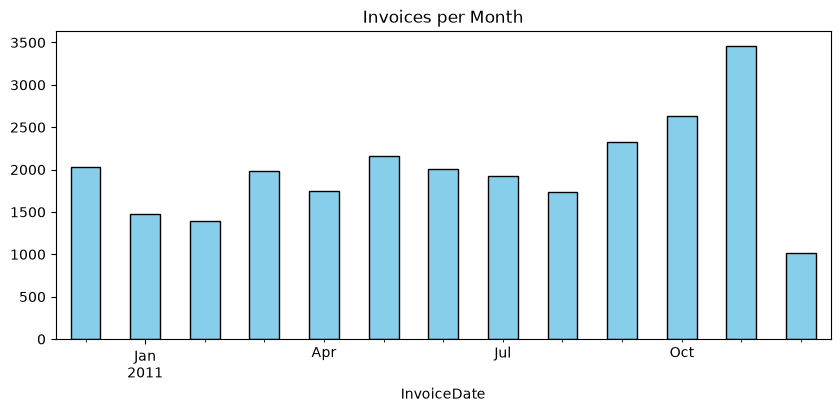

In [24]:
dates = pd.to_datetime(df["InvoiceDate"])                    
monthly = df.groupby(dates.dt.to_period("M"))["InvoiceNo"].nunique()
monthly.plot(
    kind="bar", 
    figsize=(10, 4), 
    color="skyblue",
    edgecolor="black",
    title="Invoices per Month"
    )
plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 23
هر مشتری به‌طور معمول چند فاکتور دارد؟

</div>

In [27]:
invoices_per_customer = df.groupby("CustomerID")["InvoiceNo"].nunique()      # محاسبه موقت
print(invoices_per_customer.describe())
print("One-time customers (%):", round((invoices_per_customer == 1).mean() * 100, 2))

count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64
One-time customers (%): 30.03


<div dir="rtl" style="text-align: right">

---

### Question 24
مشتریان با بیشترین و کمترین تعداد فاکتور چه تفاوتی دارند؟

</div>

In [ ]:
print("most bought:")
print(invoices_per_customer.sort_values(ascending=False).head(5))  
print("least bought:")
print(invoices_per_customer.sort_values().head(5))       

most bought
CustomerID
14911.0    248
12748.0    224
17841.0    169
14606.0    128
15311.0    118
Name: InvoiceNo, dtype: int64
least bought:
CustomerID
18278.0    1
18262.0    1
12361.0    1
12357.0    1
12355.0    1
Name: InvoiceNo, dtype: int64


<div dir="rtl" style="text-align: right">

---

## بخش ۷: روابط بین ویژگی‌ها

### Question 25
ماتریس همبستگی ویژگی‌های عددی را محاسبه کنید.

ماتریس همبستگی (Correlation Matrix) جدولی است که نشان می‌دهد بین ستون‌های عددی یک دیتاست چه میزان رابطه وجود دارد.

مقدار همبستگی بین -1 تا +1 است:
- نزدیک به +1: رابطه مثبت؛ با افزایش یک متغیر، متغیر دیگر هم معمولاً افزایش پیدا می‌کند.
- نزدیک به -1: رابطه منفی؛ با افزایش یک متغیر، متغیر دیگر معمولاً کاهش پیدا می‌کند.
- نزدیک به 0: رابطه خطی ضعیف یا تقریباً بدون رابطه.




</div>

In [39]:
correlation_matrix = (
    df.drop(columns=["CustomerID"], errors="ignore")
      .corr(numeric_only=True)
)

print(correlation_matrix)

           Quantity  UnitPrice
Quantity   1.000000  -0.001235
UnitPrice -0.001235   1.000000


<div dir="rtl" style="text-align: right;">

### تفسیر ماتریس همبستگی

ضریب همبستگی بین `Quantity` و `UnitPrice` برابر با `-0.001235` است که به صفر بسیار نزدیک است.

بنابراین، بین تعداد محصولات خریداری‌شده و قیمت هر واحد، تقریباً هیچ رابطه خطی وجود ندارد.

مقادیر `1.000` نیز نشان‌دهنده همبستگی کامل هر ستون با خودش است.

**نتیجه:** این دو ویژگی در داده‌های فعلی رابطه خطی قابل‌توجهی با یکدیگر ندارند و این نتیجه به‌تنهایی اطلاعاتی درباره ریزش مشتری ارائه نمی‌دهد.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 26
Heatmap همبستگی رسم کنید.

هدف این سؤال، نمایش تصویری روابط بین ویژگی‌ها با استفاده از Heatmap است تا بتوان:

ویژگی‌های با همبستگی زیاد را سریع‌تر شناسایی کرد.

الگوهای موجود در داده را به صورت بصری مشاهده کرد.

ویژگی‌های مرتبط با متغیر هدف را راحت‌تر پیدا کرد.

وجود هم‌خطی (Multicollinearity) را بررسی نمود.


#### در این heatmap در Heatmap، رنگ‌های سبز نشان‌دهنده همبستگی مثبت و رنگ‌های سفید نشان‌دهنده همبستگی منفی هستند.


</div>

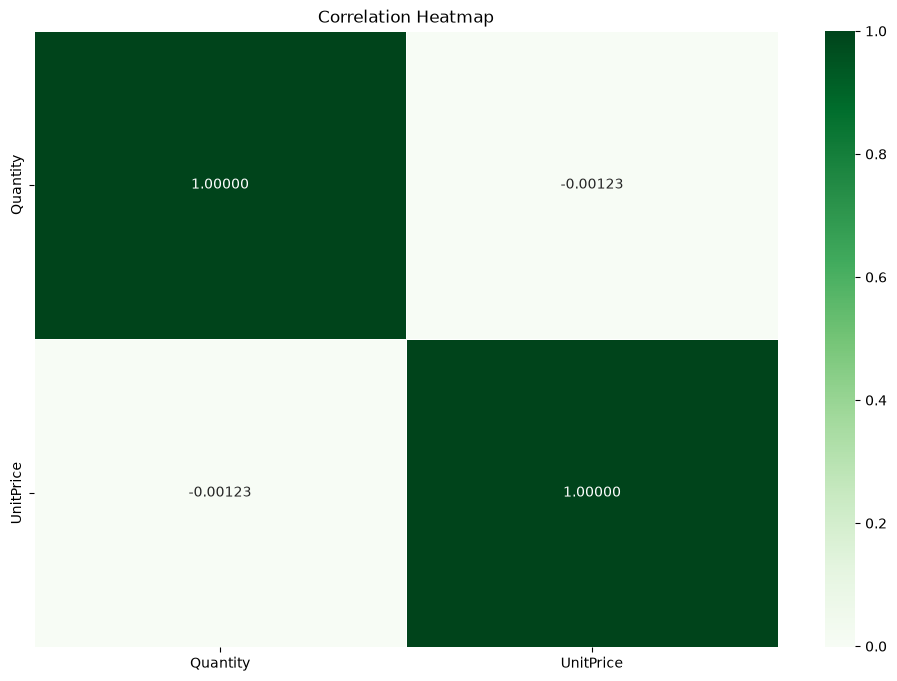

In [ ]:
correlation_matrix = (
    df.drop(columns=["CustomerID"], errors="ignore")
      .corr(numeric_only=True)
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Greens",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

<div dir="rtl" style="text-align: right">

---

### Question 27
Scatter Plot تعداد در برابر قیمت را رسم کنید.

</div>

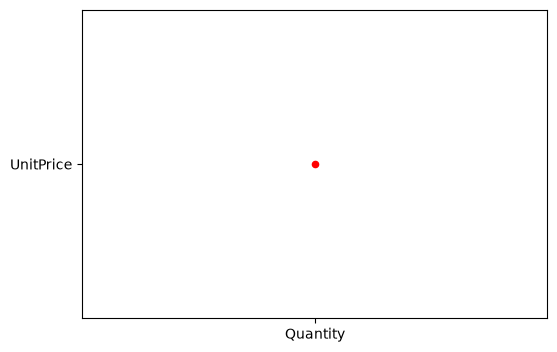

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(
    ["Quantity"], 
    ["UnitPrice"], 
    s=20,
    color = "red"
    )

plt.show()

<div dir="rtl" style="text-align: right">

---

## بخش ۸: تحلیل چندمتغیره

### Question 28
آمار Quantity و UnitPrice را برای سطرهای لغوشده و غیرلغوشده مقایسه کنید.

</div>

In [41]:
top = df["Country"]
top = top.value_counts()
top = top.head(5)
top5 = top.index
print(df[df["Country"].isin(top5)].groupby("Country")[["Quantity", "UnitPrice"]].agg(["mean", "median"]))

                 Quantity        UnitPrice       
                     mean median      mean median
Country                                          
EIRE            17.403245   10.0  5.911077   2.10
France          12.911067   10.0  5.028864   1.79
Germany         12.369458   10.0  3.966930   1.95
Spain           10.589814    6.0  4.987544   2.08
United Kingdom   8.605486    3.0  4.532422   2.10


<div dir="rtl" style="text-align: right">

---

### Question 29
سه پروفایل مشتری تعریف کنید: کم‌فعالیت، میانی و پرفعالیت.

</div>

In [ ]:
profile_group = pd.cut(
    invoices_per_customer, bins=[0, 2, 10, np.inf],
    labels=["Low (1-2)", "Medium (3-10)", "High (>10)"]
    )

line_value = df["Quantity"] * df["UnitPrice"]      
total_spend = line_value.groupby(df["CustomerID"]).sum()

summary = pd.DataFrame({
    "customers": profile_group.value_counts(),
    "total_spend": total_spend.groupby(profile_group).sum()})
summary["spend_share_%"] = (summary["total_spend"] / summary["total_spend"].sum() * 100).round(1)
print(summary)

               customers  total_spend  spend_share_%
InvoiceNo                                           
Low (1-2)           2130   882724.861           10.6
Medium (3-10)       1783  2782196.713           33.5
High (>10)           459  4635144.240           55.8


<div dir="rtl" style="text-align: right">

---

## گزارش نهایی Data Understanding

### Question 30
مهم‌ترین ویژگی‌های مرتبط با ریزش مشتری کدام‌اند؟


**جواب:** `InvoiceDate` (آخرین خرید و روند)، `CustomerID` (کلید ساخت رفتار مشتری)، `InvoiceNo` (تعداد خرید و لغو)، `Quantity` و `UnitPrice` (حجم و ارزش خرید). ستون‌های خام به‌تنهایی کم‌ارزش‌اند و ارزش اصلی در ویژگی‌های ساخته‌شده از آن‌هاست.



</div>

<div dir="rtl" style="text-align: right">

---

### Question 31
کدام ویژگی‌ها برای خوشه‌بندی و مدل‌سازی آینده ارزش بیشتری دارند؟

**جواب:** ویژگی‌های LRFM شامل Length (مدت سابقه مشتری از اولین خرید)، Recency (فاصله زمانی از آخرین خرید)، Frequency (تعداد فاکتورهای معتبر) و Monetary (ارزش کل خریدهای معتبر) از مهم‌ترین ویژگی‌ها برای خوشه‌بندی و مدل‌سازی هستند. همچنین ویژگی‌هایی مانند روند تغییرات خرید، نرخ لغو سفارش و تعداد مرجوعی‌ها می‌توانند به شناسایی الگوهای رفتاری و پیش‌بینی ریزش مشتریان کمک کنند.

</div>

<div dir="rtl" style="text-align: right">

---

### Question 32
چه مشکلاتی در داده مشاهده شد؟

**جواب:** در بررسی اولیه داده‌ها، مشکلات زیر مشاهده شد:

- حدود ۲۵٪ مقادیر گمشده در ستون `CustomerID`
- حدود ۱٪ رکورد تکراری
- وجود فاکتورهای لغوشده (با پیشوند C) و مقادیر منفی در `Quantity`
- وجود مقادیر صفر یا منفی در `UnitPrice`
- وجود کدهای غیرمحصولی در `StockCode`
- وجود داده‌های پرت (Outliers) و مقادیر غیرعادی
- ناقص بودن اطلاعات ماه پایانی دیتاست
- عدم توازن جغرافیایی و تمرکز بیش از حد تراکنش‌ها در بریتانیا

**نتیجه‌گیری:** این مشکلات باید در مرحله Data Preparation بررسی و مدیریت شوند تا داده‌ها برای تحلیل رفتار مشتریان و ساخت مدل پیش‌بینی ریزش آماده شوند.
</div>

<div dir="rtl" style="text-align: right">

---

### Question 33
اگر فقط اجازه استفاده از ۵ ویژگی را داشته باشید، کدام ویژگی‌ها را انتخاب می‌کنید؟


**جواب:** `CustomerID`، `InvoiceDate`، `InvoiceNo`، `Quantity` و `UnitPrice`. از این‌ها می‌توان Length، Recency، Frequency و Monetary را ساخت.


</div>

<div dir="rtl" style="text-align: right">

---

### Question 34
آیا داده برای ورود به مرحله Data Preparation آماده است؟


**جواب:** بله

</div>